#  📃 Leaked — India's Exam Paper Crisis, 2004–2026
### An Exploratory Data Analysis of 110 Documented Exam Paper Leak Incidents

---

**Table of Contents**
1. [Imports](#1) &nbsp;·&nbsp; 2. [Load & First Look](#2) &nbsp;·&nbsp; 3. [Data Cleaning](#3) &nbsp;·&nbsp;
4. [Feature Engineering](#4) &nbsp;·&nbsp; 5. [Data Dictionary & Coverage](#5) &nbsp;·&nbsp;
6. [Exploratory Data Analysis](#6) &nbsp;·&nbsp; 7. [Limitations](#7) &nbsp;·&nbsp; 8. [Conclusion](#8)

> **A note on this revision:** this notebook fixes a date-parsing bug, a plotting parameter bug, and a
> misleading-average issue found in the original draft; tightens the exam-sector categorization (the
> catch-all "Other" bucket shrinks from 25.5% to 5.5% of incidents); adds two analyses the cleaning steps
> had prepared for but never used (conducting-body repeat offenders, source confidence / leak-status
> verification); and adds explicit reporting-coverage caveats throughout so every average is honest about
> its denominator. Every output below was generated by a single, linear, top-to-bottom run of the cells
> as they appear — nothing here is a leftover from an earlier, different run.

## 1. Import Libraries <a id='1'></a>
NumPy, pandas, Matplotlib and Seaborn cover everything needed here: data wrangling and the full chart set. A single theme is configured once so every chart below shares the same visual language instead of each cell picking its own palette.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# ---- One consistent visual theme for the whole notebook ----
sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#3A4A5C",
    "axes.labelcolor": "#2A2F36",
    "text.color": "#2A2F36",
    "figure.dpi": 110,
})

# A small, deliberate palette used consistently across every chart below,
# rather than a different named seaborn palette per cell.
C = {
    "primary":  "#A6423D",   # deep red  -- main emphasis / "State" / leaks
    "secondary":"#3A4A5C",   # slate navy -- contrast series / "Central"
    "accent":   "#C9973F",   # muted gold -- tertiary accent
    "muted":    "#94A0AA",   # neutral grey -- de-emphasis / "Other"
    "good":     "#4C6B4F",   # muted green -- "Confirmed" / verified only
}
def seq_palette(n, color=C["primary"]):
    """Sequential ramp with exactly n colors -- avoids seaborn's palette-length mismatch warnings."""
    return sns.light_palette(color, n_colors=n, reverse=True)

def annotate_bars(ax, fmt="{:.0f}", orient="v", **kwargs):
    """Label each bar with its data value. orient='v': vertical bars, value = height.
    orient='h': horizontal bars, value = width. (Bar *width* on a vertical chart is just
    the fixed geometric bar thickness, e.g. 0.8 -- never the data value; this must be
    explicit rather than guessed, which was the source of an earlier bug.)"""
    for container in ax.containers:
        if orient == "v":
            labels = [fmt.format(v.get_height()) if v.get_height() else "" for v in container]
        else:
            labels = [fmt.format(v.get_width()) if v.get_width() else "" for v in container]
        ax.bar_label(container, labels=labels, padding=3, fontweight="bold", fontsize=10, **kwargs)

## 2. Load the Dataset & First Look <a id='2'></a>
The CSV is expected in the same folder as this notebook (swap the path below if yours lives elsewhere).

In [2]:
df = pd.read_csv('paper_leaks.csv')
df.shape

(110, 18)

In [3]:
df.head()

,incident_id,date,era,exam_name,conducting_body,body_type,area,leak_status,action_taken,note,arrests,convictions,aspirants_affected,linked_deaths,deaths_note,source_name,source_url,confidence
0,PL-0001,2004-04-11,UPA (2004-May2014),All India Pre-Medical Test (AIPMT/CBSE-PMT) 2004,Central Board of Secondary Education (CBSE),Central,All India,Confirmed,Exam cancelled + Arrests-FIR + Probe (CBI/SIT),Physics and chemistry papers leaked in New Del...,2.0,NaN,NaN,NaN,NaN,The Tribune,https://www.tribuneindia.com/2004/20040412/mai...,High
1,PL-0002,2006-06-01,UPA (2004-May2014),Himachal Pradesh Combined Pre-Medical Test (HP...,Himachal Pradesh University,State,Himachal Pradesh,Confirmed,Retest + Arrests-FIR,HP-CPMT medical entrance paper leaked via a to...,NaN,NaN,NaN,NaN,NaN,The Tribune,https://www.tribuneindia.com/2006/20060831/him...,Medium
2,PL-0003,2008-01-01,UPA (2004-May2014),Vyapam Patwari Recruitment Examination 2008,Madhya Pradesh Professional Examination Board ...,State,Madhya Pradesh,Confirmed,Arrests-FIR + Probe (CBI/SIT),Accused produced forged educational certificat...,NaN,10.0,NaN,NaN,NaN,The420.in,https://the420.in/vyapam-scam-cbi-court-patwar...,High
3,PL-0004,2009-07-08,UPA (2004-May2014),MP Pre-Medical Test (PMT) 2009,Vyapam (MPPEB),State,Madhya Pradesh,Confirmed,Arrests-FIR + Probe (CBI/SIT),Paid solvers/impersonators sat the exam in pla...,NaN,NaN,114.0,NaN,NaN,The Free Press Journal,https://www.freepressjournal.in/education/indo...,High
4,PL-0005,2010-06-06,UPA (2004-May2014),RRB Mumbai 2010 recruitment exam (Assistant Lo...,"Railway Recruitment Board (RRB), Mumbai",Central,All India,Confirmed,Arrests-FIR + Probe (CBI/SIT),CBI registered a case on 15 June 2010 over the...,15.0,10.0,NaN,NaN,NaN,The Week,https://www.theweek.in/wire-updates/national/2...,High


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 110 entries, 0 to 109
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   incident_id         110 non-null    str    
 1   date                110 non-null    str    
 2   era                 110 non-null    str    
 3   exam_name           110 non-null    str    
 4   conducting_body     110 non-null    str    
 5   body_type           110 non-null    str    
 6   area                110 non-null    str    
 7   leak_status         110 non-null    str    
 8   action_taken        110 non-null    str    
 9   note                110 non-null    str    
 10  arrests             63 non-null     float64
 11  convictions         10 non-null     float64
 12  aspirants_affected  44 non-null     float64
 13  linked_deaths       4 non-null      float64
 14  deaths_note         4 non-null      str    
 15  source_name         110 non-null    str    
 16  source_url         

In [5]:
df.describe().round(2)

,arrests,convictions,aspirants_affected,linked_deaths
count,63.00,10.00,44.00,4.00
mean,26.86,11.40,511626.55,10.25
std,46.70,11.95,890520.28,9.91
min,0.00,0.00,114.00,1.00
25%,4.50,3.25,63250.00,3.25
50%,12.00,10.00,133103.00,8.50
75%,23.50,11.00,600000.00,15.50
max,266.00,34.00,4800000.00,23.00


**First-look notes:**
- 110 rows, 18 raw columns — one row per incident.
- `arrests`, `convictions`, `aspirants_affected`, `linked_deaths` are heavily sparse (counts of 63, 10, 44 and 4
  respectively out of 110 — visible in `.describe()` above, which only counts non-null values). This sparsity
  is real and important: it means most of this notebook's incident-level averages describe *"where reported,"*
  not *"in general."* We'll carry that distinction through every relevant section rather than only mentioning
  it once here.

## 3. Cleaning the Dataset <a id='3'></a>

### 3.1 Standardizing the Date Column
The raw `date` column is ISO-formatted text (`YYYY-MM-DD`), so we parse it without forcing a mismatched explicit format -- forcing the wrong `format=` string here is a classic silent-failure trap (it can produce `NaT` for every row, or worse, silently swap day/month for dates where both happen to be ≤12).

In [6]:
df['date'] = pd.to_datetime(df['date'], errors='coerce')
print('Unparseable dates:', df['date'].isna().sum(), 'out of', len(df))
df['year'] = df['date'].dt.year
df[['incident_id','date','year']].head()

Unparseable dates: 0 out of 110


,incident_id,date,year
0,PL-0001,2004-04-11,2004
1,PL-0002,2006-06-01,2006
2,PL-0003,2008-01-01,2008
3,PL-0004,2009-07-08,2009
4,PL-0005,2010-06-06,2010


### 3.2 Handling Missing Numeric Values
`arrests`, `convictions`, `aspirants_affected` and `linked_deaths` are frequently unreported rather than genuinely zero. We coerce them to numeric but deliberately **do not** fill missing values with 0: doing so before averaging would silently treat *"not reported"* as *"confirmed none"* and understate every mean. We keep `NaN` as `NaN` -- `.sum()` already ignores it correctly -- and add explicit `_reported` flags so any later reader can see exactly which incidents are contributing to a given average.

In [7]:
numeric_cols = ['arrests', 'convictions', 'aspirants_affected', 'linked_deaths']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    df[f'{col}_reported'] = df[col].notna()

coverage = pd.DataFrame({
    'reported_n': [df[f'{c}_reported'].sum() for c in numeric_cols],
    'reported_pct': [round(df[f'{c}_reported'].mean()*100,1) for c in numeric_cols],
}, index=numeric_cols)
coverage

,reported_n,reported_pct
arrests,63,57.3
convictions,10,9.1
aspirants_affected,44,40.0
linked_deaths,4,3.6


### 3.3 Stripping Whitespace & Standardizing Case
Several text columns mix casing and stray whitespace from manual data entry.

In [8]:
for col in ['conducting_body', 'body_type', 'leak_status']:
    df[col] = df[col].str.strip().str.title()
df['leak_status'].value_counts()

leak_status
Confirmed    89
Alleged      13
Denied        5
Suspected     3
Name: count, dtype: int64

### 3.4 Correcting `leak_status` & `conducting_body` Labels
Manual entry produced spelling/casing variants of the same real-world entity (e.g. several ways of writing "Vyapam" or "CBSE"). We map these to single canonical labels so later `groupby` counts aren't artificially split.

In [9]:
corrections = {
    # leak_status variants
    'Suspected': 'Alleged',
    # conducting_body variants -> canonical short names
    # (verified against the full raw unique-value list -- note Chhattisgarh's
    # "CG Vyapam/CGPEB" is a distinct state body and is deliberately NOT merged
    # into Madhya Pradesh's Vyapam despite the shared nickname)
    'Cbse': 'CBSE',
    'Central Board Of Secondary Education (Cbse)': 'CBSE',
    'Ssc': 'SSC',
    'Staff Selection Commission (Ssc)': 'SSC',
    'All India Institute Of Medical Sciences (Aiims)': 'AIIMS',
    'Aiims New Delhi': 'AIIMS',
    'Vyapam (Mppeb)': 'Vyapam (MPPEB)',
    'Madhya Pradesh Professional Examination Board (Vyapam)': 'Vyapam (MPPEB)',
    'Madhya Pradesh Professional Examination Board (Vyapam/Mpesb)': 'Vyapam (MPPEB)',
    'Madhya Pradesh Professional Examination Board (Vyapam/Mppeb)': 'Vyapam (MPPEB)',
    'Madhya Pradesh Employees Selection Board (Esb)': 'MP Employees Selection Board (ESB)',
    'Madhya Pradesh Employees Selection Board (Esb, Formerly Peb)': 'MP Employees Selection Board (ESB)',
}
df['leak_status'] = df['leak_status'].replace(corrections)
df['conducting_body'] = df['conducting_body'].replace(corrections)
print('leak_status categories after cleaning:', df['leak_status'].unique().tolist())
df['leak_status'].value_counts()

leak_status categories after cleaning: ['Confirmed', 'Alleged', 'Denied']


leak_status
Confirmed    89
Alleged      16
Denied        5
Name: count, dtype: int64

### 3.5 Cleaning the `action_taken` Column
This column mixes spacing around `+`, inconsistent ordering of the same actions, and varying probe-agency
abbreviations. We standardize spacing and ordering so identical action sets compare equal, then derive a
high-level `action_summary` for charting.

In [10]:
df['action_taken'] = df['action_taken'].str.replace(r'\s*\+\s*', ' + ', regex=True)

def sort_actions(action_string):
    if pd.isna(action_string):
        return action_string
    actions = [a.strip() for a in action_string.split('+')]
    actions.sort()
    return ' + '.join(actions)

df['action_taken'] = df['action_taken'].apply(sort_actions)

def summarize_action(action):
    a = str(action).lower()
    if 'cancelled' in a or 'retest' in a:
        return 'Exam Cancelled / Retest'
    elif 'arrest' in a and 'probe' in a:
        return 'Arrests & Investigation (No Cancellation)'
    elif 'arrest' in a:
        return 'Arrests Only (No Cancellation)'
    elif 'probe' in a:
        return 'Investigation Ongoing (No Arrests Yet)'
    else:
        return 'No Action Reported'

df['action_summary'] = df['action_taken'].apply(summarize_action)
df[['action_taken', 'action_summary']].head(6)

,action_taken,action_summary
0,Arrests-FIR + Exam cancelled + Probe (CBI/SIT),Exam Cancelled / Retest
1,Arrests-FIR + Retest,Exam Cancelled / Retest
2,Arrests-FIR + Probe (CBI/SIT),Arrests & Investigation (No Cancellation)
3,Arrests-FIR + Probe (CBI/SIT),Arrests & Investigation (No Cancellation)
4,Arrests-FIR + Probe (CBI/SIT),Arrests & Investigation (No Cancellation)
5,Arrests-FIR + Probe (CBI/SIT),Arrests & Investigation (No Cancellation)


### 3.6 Normalizing the `area` Column into a Clean `state` Field
Locations mix state names with district/city detail in parentheses (and occasionally a second location after a `/`), which would fragment a geographic rollup. We keep the raw text in `area` and add a clean `state` column for aggregation.

In [11]:
import re

def normalize_state(area):
    if area == 'All India':
        return 'All India'
    primary = area.split(' / ')[0].strip()
    primary = re.sub(r'\s*\([^)]*\)\s*$', '', primary).strip()
    return primary

df['state'] = df['area'].apply(normalize_state)
df[['area','state']].drop_duplicates().head(8)

,area,state
0,All India,All India
1,Himachal Pradesh,Himachal Pradesh
2,Madhya Pradesh,Madhya Pradesh
6,Andaman & Nicobar Islands,Andaman & Nicobar Islands
7,Uttar Pradesh (Kanpur/Lucknow),Uttar Pradesh
8,Chhattisgarh,Chhattisgarh
9,Uttar Pradesh,Uttar Pradesh
13,Delhi,Delhi


## 4. Feature Engineering <a id='4'></a>

### 4.1 Categorizing Exams by Sector
The original keyword rules left a 25.5%-of-all-incidents "Other" bucket -- by far the *largest* single
category, which made the sector breakdown less informative than it should be. Looking at what actually fell
into "Other" (SSC/PCS-style admin exams, revenue-officer roles like Patwari/Tehsildar/Lekhpal, railway
recruitment, and a few teaching-adjacent titles like "Assistant Professor") let us extend the keyword rules
so the catch-all shrinks to the incidents that are genuinely one-offs.

In [12]:
def categorize_exam(name):
    n = str(name).lower()
    if any(w in n for w in ['medical','neet','aipmt','pmt','health','nurse','aiims','pharmacist']):
        return 'Medical / Healthcare'
    elif any(w in n for w in ['police','constable','sub-inspector','army','guard']):
        return 'Police / Defence'
    elif any(w in n for w in ['railway','rrb','loco pilot','rrc ']):
        return 'Railways / Transport'
    elif any(w in n for w in ['teacher','tet','school','education','professor','ugc-net','ugc net']):
        return 'Teaching / Education'
    elif any(w in n for w in ['engineer','aieee','technical']):
        return 'Engineering / Technical'
    elif any(w in n for w in ['board','class 10','class 12','hsc','sslc']):
        return 'School Board Exams'
    elif any(w in n for w in ['psc','pcs','civil service','administrative','clerk','patwari','ssc','cgl',
                                'tehsildar','lekhpal','talathi','panchayat','judicial','hcs ','office assistant']):
        return 'Civil Services / Admin'
    else:
        return 'Other State/Central Exams'

df['exam_category'] = df['exam_name'].apply(categorize_exam)
cat_check = df['exam_category'].value_counts()
print('"Other" bucket: {} incidents ({:.1f}% of 110) -- down from 28 incidents (25.5%) in the original rules'
      .format(cat_check.get('Other State/Central Exams', 0), cat_check.get('Other State/Central Exams', 0)/110*100))
cat_check

"Other" bucket: 6 incidents (5.5% of 110) -- down from 28 incidents (25.5%) in the original rules


exam_category
Civil Services / Admin       32
Medical / Healthcare         20
Police / Defence             18
Teaching / Education         15
School Board Exams            9
Engineering / Technical       7
Other State/Central Exams     6
Railways / Transport          3
Name: count, dtype: int64

### 4.2 Standardizing Equivalent Exam Names
The same real-world exam is often entered under several names across years (NEET / AIPMT / state PMTs are historically the same medical-entrance lineage, for example). We unify these so repeat-target analysis isn't fragmented by year-specific naming.

In [13]:
def standardize_exam_name(exam):
    e = str(exam).lower()
    if any(k in e for k in ['neet', 'aipmt', 'pmt', 'pre-medical']):
        return 'NEET / Pre-Medical Entrance (UG)'
    elif 'cbse' in e and ('class' in e or 'board' in e):
        return 'CBSE Class 10/12 Board Exams'
    elif any(k in e for k in ['tre', 'tet', 'teacher eligibility']):
        return 'State Teacher Recruitment/Eligibility (TET/TRE)'
    elif 'patwari' in e:
        return 'Patwari Recruitment Exam'
    elif 'constable' in e and 'police' in e:
        return 'Police Constable Recruitment'
    elif 'sub-inspector' in e or ' si ' in e:
        return 'Police Sub-Inspector (SI) Recruitment'
    elif 'combined competitive' in e or 'psc' in e:
        return 'State PSC / Combined Competitive Exam'
    elif 'engineer' in e and any(k in e for k in ['junior', 'assistant', 'je', 'ae']):
        return 'Junior/Assistant Engineer (JE/AE) Recruitment'
    else:
        return exam

df['standardized_exam_name'] = df['exam_name'].apply(standardize_exam_name)
df['standardized_exam_name'].value_counts().head(6)

standardized_exam_name
NEET / Pre-Medical Entrance (UG)                   13
State Teacher Recruitment/Eligibility (TET/TRE)    10
State PSC / Combined Competitive Exam               8
Police Constable Recruitment                        7
Junior/Assistant Engineer (JE/AE) Recruitment       6
Patwari Recruitment Exam                            4
Name: count, dtype: int64

### 4.3 Preparing Conducting-Body Analysis (Repeat Offenders)
The cleaning step in 3.4 already canonicalized `conducting_body` labels (merging Vyapam/CBSE/ESB spelling variants) -- here we simply confirm it's ready to rank directly, which we'll use in section 6.2.

In [14]:
df['conducting_body'].value_counts().head(10)

conducting_body
Vyapam (MPPEB)                                                   10
CBSE                                                              9
Uttarakhand Subordinate Service Selection Commission (Uksssc)     4
Rajasthan Staff Selection Board (Rsmssb)                          4
Nta                                                               4
Rajasthan Public Service Commission (Rpsc)                        3
Bihar Public Service Commission (Bpsc)                            3
Jharkhand Staff Selection Commission (Jssc)                       3
AIIMS                                                             2
SSC                                                               2
Name: count, dtype: int64

In [15]:
df.shape

(110, 27)

## 5. Data Dictionary & Coverage Summary <a id='5'></a>
Before charting anything, it's worth being explicit about what each field means and -- critically -- how completely it's actually reported. This table is the single reference point for "where reported" denominators used throughout section 6.

In [16]:
data_dict = pd.DataFrame([
    ('incident_id',          'Unique ID, PL-0001..PL-0110',                         '100%'),
    ('date / year',          'Incident date (parsed) and its year',                 '100%'),
    ('era',                  'UPA (2004-May 2014) or NDA (May 2014-present)',       '100%'),
    ('exam_name',            'Full exam name as reported',                          '100%'),
    ('exam_category',        'Engineered: 8-sector rollup (section 4.1)',           '100%'),
    ('standardized_exam_name','Engineered: unifies equivalent exam names',          '100%'),
    ('conducting_body',      'Cleaned canonical name of the exam authority',        '100%'),
    ('body_type',            'State or Central authority',                          '100%'),
    ('area / state',         'Raw location text / cleaned state name',              '100%'),
    ('leak_status',          'Confirmed, Alleged, or Denied',                       '100%'),
    ('action_taken',         'Cleaned free text of the official response',          '100%'),
    ('action_summary',       'Engineered: 5-bucket rollup of action_taken',         '100%'),
    ('arrests',              'Count of arrests, where reported',                    '57.3%'),
    ('convictions',          'Count of convictions, where reported',                '9.1%'),
    ('aspirants_affected',   'Candidates affected, where reported',                 '40.0%'),
    ('linked_deaths',        'Press-reported deaths linked to the incident',        '3.6%'),
], columns=['Column', 'Meaning', 'Coverage'])

data_dict.style.set_properties(**{'text-align':'left'}).set_table_styles(
    [{'selector':'th','props':[('text-align','left'), ('background-color', C['secondary']), ('color','white')]}]
).hide(axis='index')

Column,Meaning,Coverage
incident_id,"Unique ID, PL-0001..PL-0110",100%
date / year,Incident date (parsed) and its year,100%
era,UPA (2004-May 2014) or NDA (May 2014-present),100%
exam_name,Full exam name as reported,100%
exam_category,Engineered: 8-sector rollup (section 4.1),100%
standardized_exam_name,Engineered: unifies equivalent exam names,100%
conducting_body,Cleaned canonical name of the exam authority,100%
body_type,State or Central authority,100%
area / state,Raw location text / cleaned state name,100%
leak_status,"Confirmed, Alleged, or Denied",100%


> **Reading this table:** the top block (100%-covered fields) supports incident-level counting -- "how many
> incidents," "which state," "which sector" -- with full confidence. The bottom block (`arrests` down to
> `linked_deaths`) supports **magnitude** questions -- "how many people," "how many arrests" -- but only for
> the fraction of incidents where a number was ever publicly reported. Every average built on those four
> columns in section 6 is explicitly labeled *"where reported."*

## 6. Exploratory Data Analysis <a id='6'></a>

**Objective:** perform a structured EDA on the 110-incident dataset to uncover operational vulnerabilities,
regional hotspots, historical trends, and the gap between arrests made and convictions secured.

**Four analytical pillars:**
1. **Temporal & Era Distribution** -- incident frequency over time, and across UPA vs. NDA administrations.
2. **Sector & Exam Vulnerability** -- which exam categories, specific exams, and conducting bodies recur.
3. **Geographic & Administrative Distribution** -- State vs. Central jurisdiction, and regional hotspots.
4. **Accountability Gap** -- government response patterns, and the arrest-to-conviction funnel.

### 6.1 Temporal & Era Distribution <a id='6.1'></a>
**6.1.1 Incident frequency per year, 2004-2026**

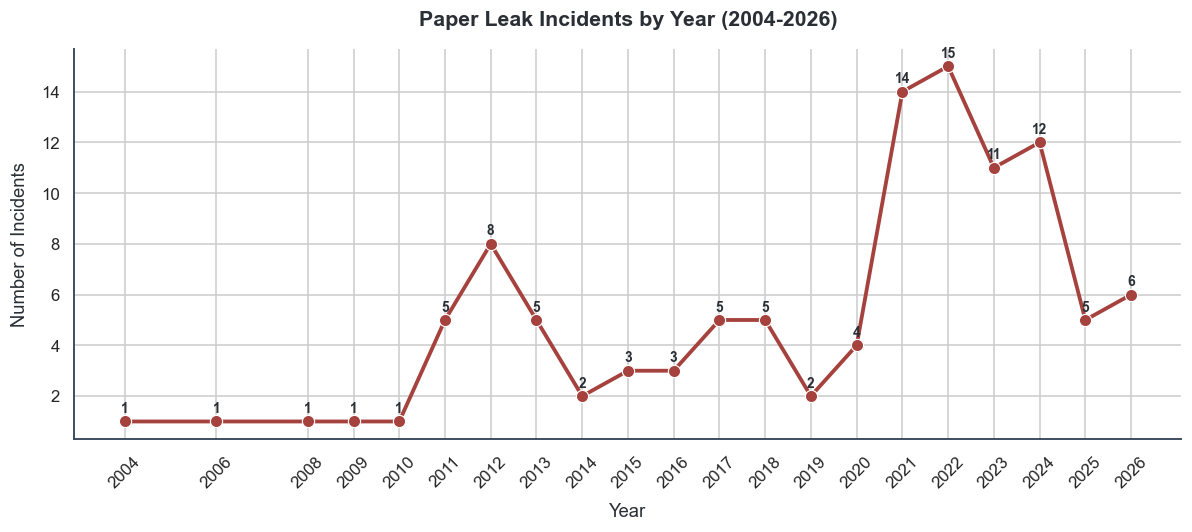

In [17]:
yearly_counts = df.groupby('year').size().reset_index(name='counts')

plt.figure(figsize=(11, 5))
ax = sns.lineplot(data=yearly_counts, x='year', y='counts', marker='o',
                   color=C['primary'], linewidth=2.5, markersize=8)
plt.title('Paper Leak Incidents by Year (2004-2026)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Year', fontsize=12, labelpad=8)
plt.ylabel('Number of Incidents', fontsize=12, labelpad=8)
for _, row in yearly_counts.iterrows():
    plt.text(row['year'], row['counts'] + 0.35, str(int(row['counts'])), ha='center', fontsize=9, fontweight='bold')
plt.xticks(yearly_counts['year'], rotation=45)
plt.gca().spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

In [18]:
baseline = yearly_counts.query('year <= 2020')['counts'].sum()
escalation = yearly_counts.query('year >= 2021')['counts'].sum()
peak = yearly_counts.loc[yearly_counts['counts'].idxmax()]
print(f'2004-2020 baseline: {baseline} incidents over 17 years (~{baseline/17:.1f}/year)')
print(f'2021-2026 escalation: {escalation} incidents over 6 years (~{escalation/6:.1f}/year)')
print(f'{escalation} of 110 = {escalation/110*100:.0f}% of all recorded incidents fall in just 2021-2026')
print(f'Peak year: {int(peak.year)} with {int(peak.counts)} incidents')

2004-2020 baseline: 47 incidents over 17 years (~2.8/year)
2021-2026 escalation: 63 incidents over 6 years (~10.5/year)
63 of 110 = 57% of all recorded incidents fall in just 2021-2026
Peak year: 2022 with 15 incidents


**Reading this trend:** the frequency clearly accelerates after 2020, but two very different stories
could produce the same chart -- *(a)* paper leaks becoming genuinely more frequent, or *(b)* leaks becoming
far more likely to be **detected and reported** once they happen, thanks to WhatsApp/Telegram circulation,
RTI-driven disclosure, and dedicated exam-news outlets that didn't exist in 2008. This dataset cannot
distinguish between the two -- both are almost certainly true to some degree, and the true split matters a
lot for policy but isn't something incident counts alone can resolve.

**6.1.2 Era Comparison -- UPA vs. NDA**

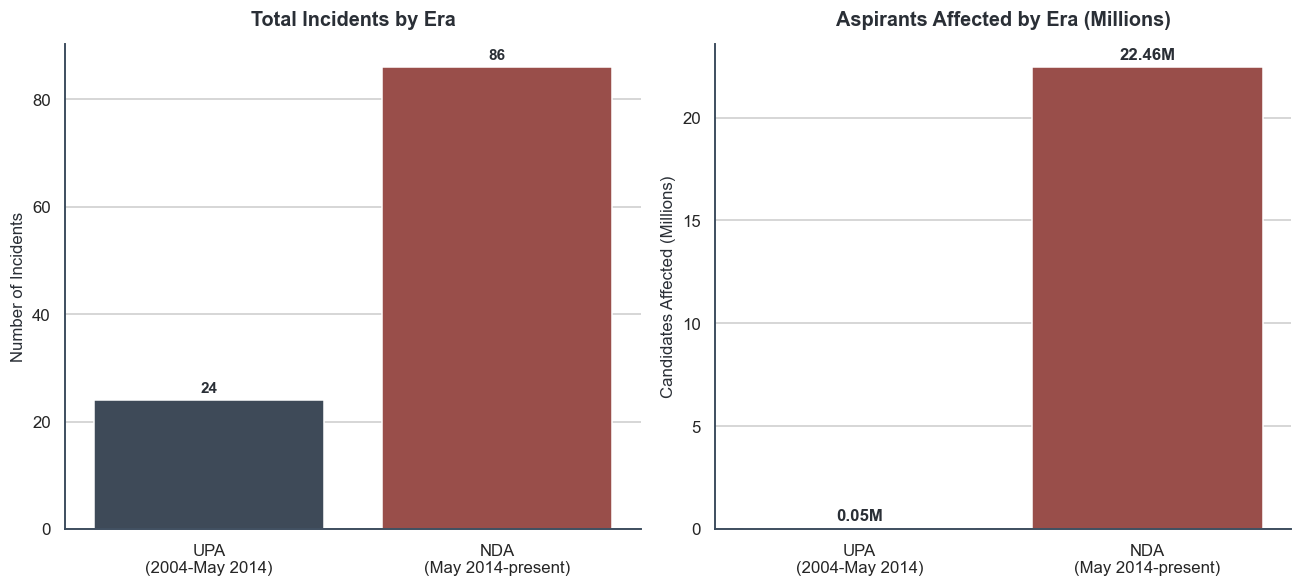

,era,total_incidents,years_covered,incidents_per_year,aspirants_millions
0,NDA (May2014-now),86,12.2,7.05,22.459168
1,UPA (2004-May2014),24,10.1,2.38,0.052400


In [19]:
era_summary = df.groupby('era').agg(
    total_incidents=('incident_id', 'count'),
    total_aspirants=('aspirants_affected', 'sum'),
).reset_index()
era_summary['aspirants_millions'] = era_summary['total_aspirants'] / 1e6
era_summary['years_covered'] = era_summary['era'].map({'UPA (2004-May2014)': 10.1, 'NDA (May2014-now)': 12.2})
era_summary['incidents_per_year'] = (era_summary['total_incidents'] / era_summary['years_covered']).round(2)
era_palette = {'UPA (2004-May2014)': C['secondary'], 'NDA (May2014-now)': C['primary']}
# groupby('era') sorts alphabetically (NDA before UPA) -- force chronological order explicitly
# rather than relying on hardcoded labels matching whatever order pandas happens to produce.
era_order = ['UPA (2004-May2014)', 'NDA (May2014-now)']

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
sns.barplot(data=era_summary, x='era', y='total_incidents', hue='era', order=era_order,
            palette=era_palette, legend=False, ax=axes[0])
axes[0].set_title('Total Incidents by Era', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel(''); axes[0].set_ylabel('Number of Incidents', fontsize=11)
annotate_bars(axes[0], fmt='{:.0f}', orient='v')

sns.barplot(data=era_summary, x='era', y='aspirants_millions', hue='era', order=era_order,
            palette=era_palette, legend=False, ax=axes[1])
axes[1].set_title('Aspirants Affected by Era (Millions)', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel(''); axes[1].set_ylabel('Candidates Affected (Millions)', fontsize=11)
for ax in axes:
    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels(['UPA\n(2004-May 2014)', 'NDA\n(May 2014-present)'])
    ax.spines[['top','right']].set_visible(False)
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.2f}M', (p.get_x()+p.get_width()/2., p.get_height()),
                      ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0,3), textcoords='offset points')
plt.tight_layout()
plt.show()
era_summary[['era','total_incidents','years_covered','incidents_per_year','aspirants_millions']]

**Important caveat before reading this as a governance scorecard:** the NDA-era rate here (~7.1
incidents/year) is roughly 3x the UPA-era rate (~2.4/year) -- but for the same reason as 6.1.1, this is very
unlikely to be a clean like-for-like comparison. Media coverage, RTI activism, smartphone/social-media
circulation, and the sheer number of competitive exams and aspirants have all grown substantially since 2004,
independent of which party governed. Both eras also contain marquee scandals regardless of party -- Vyapam
began under a state government in 2009; NEET-UG 2024 broke under the NDA centre. Most leaks (80%, see 6.3)
are State-board incidents in any case, several steps removed from either central administration. **Read this
chart as a documentation trend, not a causal claim about either coalition's governance.**

### 6.2 Sector & Exam Vulnerability Analysis <a id='6.2'></a>
**6.2.1 Incidents by exam sector**

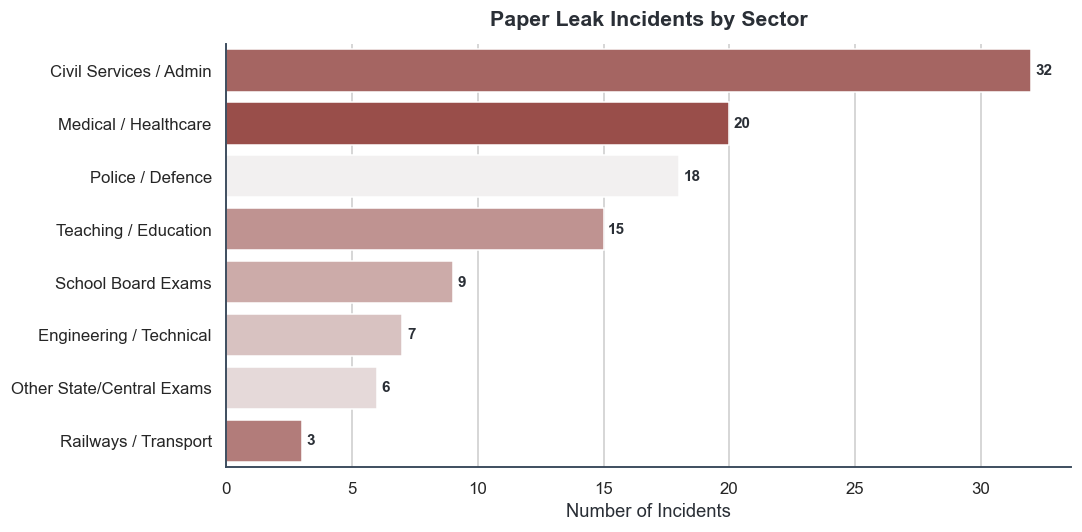

In [20]:
plt.figure(figsize=(10, 5))
order = df['exam_category'].value_counts().index
ax = sns.countplot(data=df, y='exam_category', order=order, hue='exam_category',
                    palette=seq_palette(df['exam_category'].nunique()), legend=False)
plt.title('Paper Leak Incidents by Sector', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Number of Incidents'); plt.ylabel('')
annotate_bars(ax, fmt='{:.0f}', orient='h')
plt.gca().spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

**Reading this:** Civil Services / Admin now leads at 32 incidents (29.1%) once SSC/PCS-style commissions
and revenue-officer roles (Patwari, Tehsildar, Lekhpal) are grouped together -- previously scattered across a
generic "Other" bucket. Medical/Healthcare (20, 18.2%) and Police/Defence (18, 16.4%) follow. These three
sectors alone account for 64.5% of all incidents, consistent with the underlying incentive: all three offer
secure, highly competitive government employment or medical seats, which is exactly the profile that sustains
organized "solver" networks.

**6.2.2 Top 10 most-targeted standardized exams**

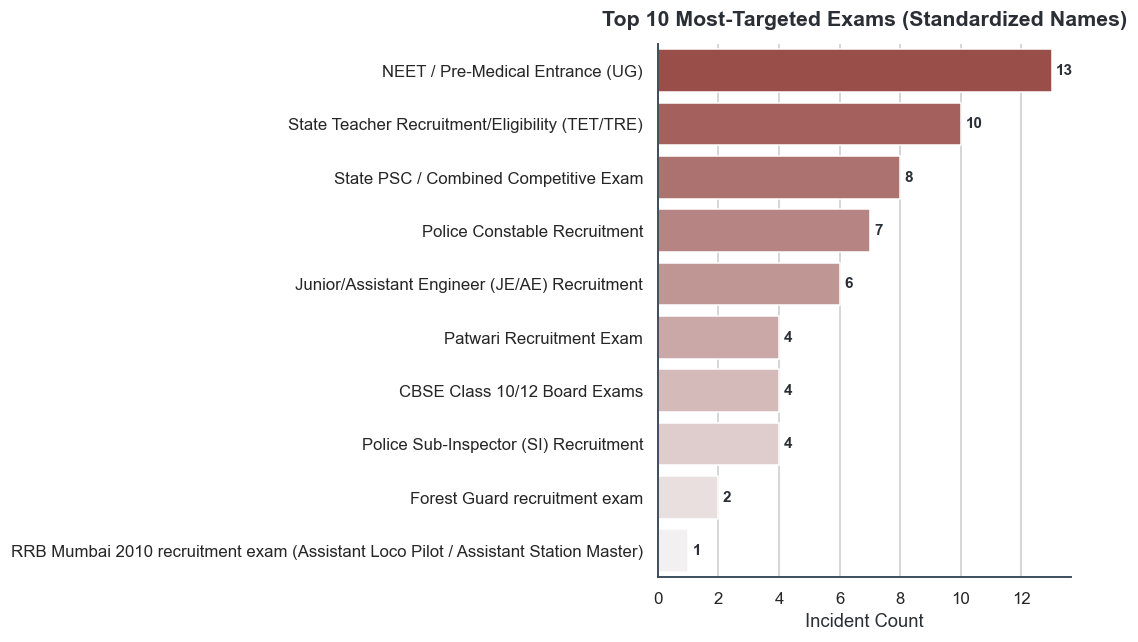

In [21]:
plt.figure(figsize=(10, 6))
top_exams = df['standardized_exam_name'].value_counts().head(10).reset_index()
top_exams.columns = ['exam', 'count']
ax = sns.barplot(data=top_exams, y='exam', x='count', hue='exam', palette=seq_palette(len(top_exams)), legend=False)
plt.title('Top 10 Most-Targeted Exams (Standardized Names)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Incident Count'); plt.ylabel('')
annotate_bars(ax, fmt='{:.0f}', orient='h')
plt.gca().spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

**6.2.3 Most-implicated conducting bodies (repeat offenders)**
The cleaning in section 3.4 canonicalized `conducting_body` spellings specifically so this ranking would be meaningful -- the original notebook cleaned this field but never actually charted it.

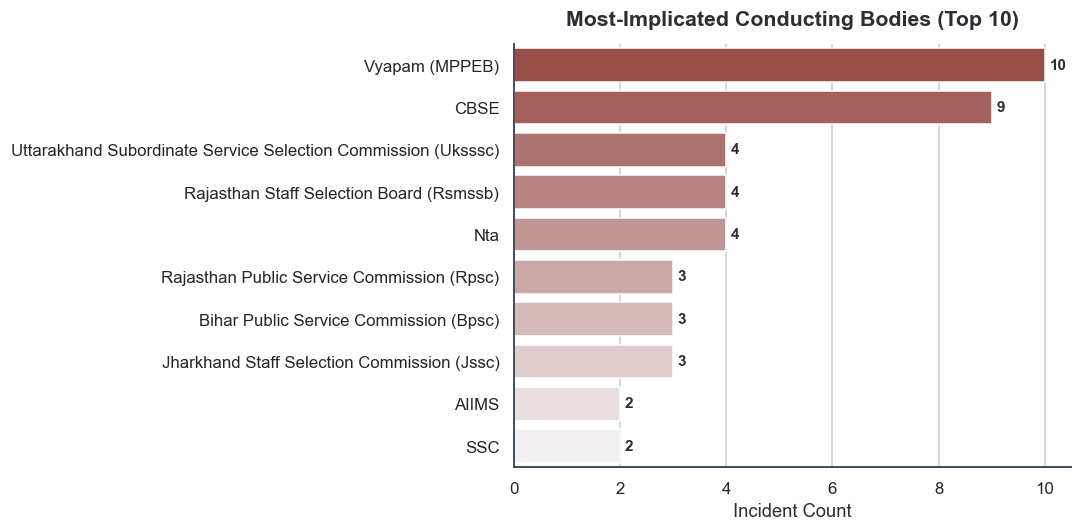

In [22]:
plt.figure(figsize=(10, 5))
top_bodies = df['conducting_body'].value_counts().head(10).reset_index()
top_bodies.columns = ['body', 'count']
ax = sns.barplot(data=top_bodies, y='body', x='count', hue='body', palette=seq_palette(len(top_bodies)), legend=False)
plt.title('Most-Implicated Conducting Bodies (Top 10)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Incident Count'); plt.ylabel('')
annotate_bars(ax, fmt='{:.0f}', orient='h')
plt.gca().spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

**Result Summary -- Sector & Exam Vulnerability.** A small number of institutions carry a disproportionate
share of incidents. **Vyapam (Madhya Pradesh's Professional Examination Board)** appears in 10 separate
incidents on its own -- the long-running scandal (2007-2015) that became the namesake for the phrase "Vyapam
scam" in Indian media. **CBSE** appears in 9. Among specific exams, **NEET / Pre-Medical Entrance** leads with
13 incidents spanning nearly the entire dataset's timeframe (its lineage runs from state PMTs and AIPMT
through to NEET-UG), impacting ~5.43M aspirants -- confirming medical-entrance exams as India's single most
recurring examination-integrity target.

### 6.3 Geographic & Administrative Distribution <a id='6.3'></a>
**6.3.1 State vs. Central authority split**
A simple two-category bar reads more precisely than a pie here and keeps the visual language consistent with the rest of the notebook.

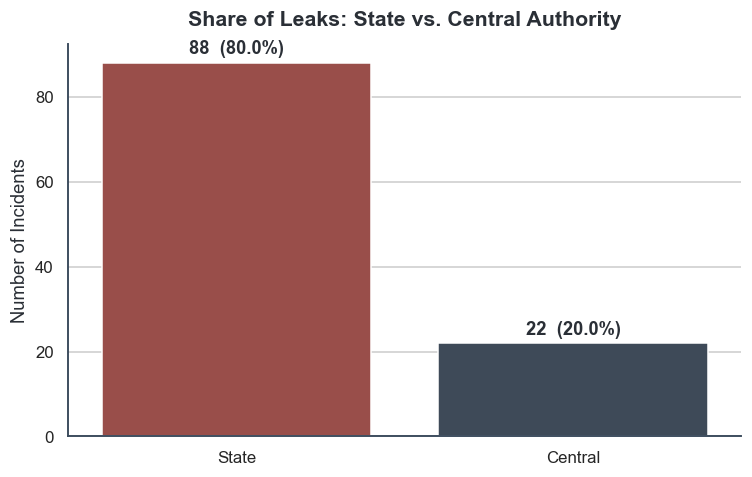

In [23]:
body_counts = df['body_type'].value_counts().reset_index()
body_counts.columns = ['body_type', 'count']
body_counts['pct'] = (body_counts['count']/len(df)*100).round(1)
palette_bt = {'State': C['primary'], 'Central': C['secondary']}

plt.figure(figsize=(7, 4.5))
ax = sns.barplot(data=body_counts, x='body_type', y='count', hue='body_type', palette=palette_bt, legend=False)
plt.title('Share of Leaks: State vs. Central Authority', fontsize=14, fontweight='bold', pad=12)
plt.xlabel(''); plt.ylabel('Number of Incidents')
for p, pct in zip(ax.patches, body_counts['pct']):
    ax.annotate(f'{int(p.get_height())}  ({pct}%)', (p.get_x()+p.get_width()/2., p.get_height()),
                ha='center', va='bottom', fontsize=12, fontweight='bold', xytext=(0,3), textcoords='offset points')
plt.gca().spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

**6.3.2 Geographic hotspots (top states/UTs)**

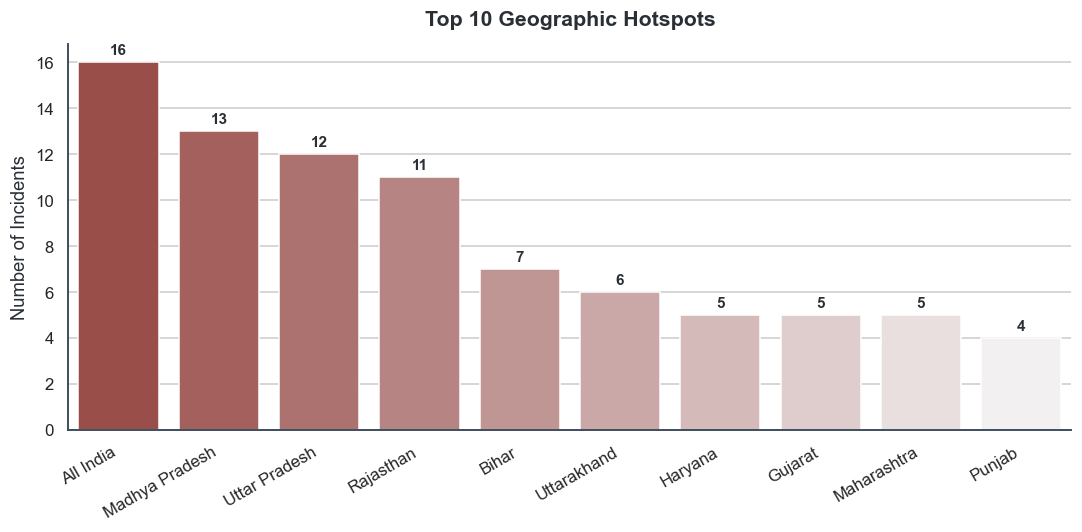

In [24]:
plt.figure(figsize=(10, 5))
top_areas = df['state'].value_counts().head(10).reset_index()
top_areas.columns = ['state', 'count']
ax = sns.barplot(data=top_areas, x='state', y='count', hue='state',
                  palette=seq_palette(len(top_areas)), legend=False)
plt.title('Top 10 Geographic Hotspots', fontsize=14, fontweight='bold', pad=12)
plt.xlabel(''); plt.ylabel('Number of Incidents')
annotate_bars(ax, fmt='{:.0f}', orient='v')
plt.xticks(rotation=30, ha='right')
plt.gca().spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

**6.3.3 Top 5 mega-leaks by candidate impact**

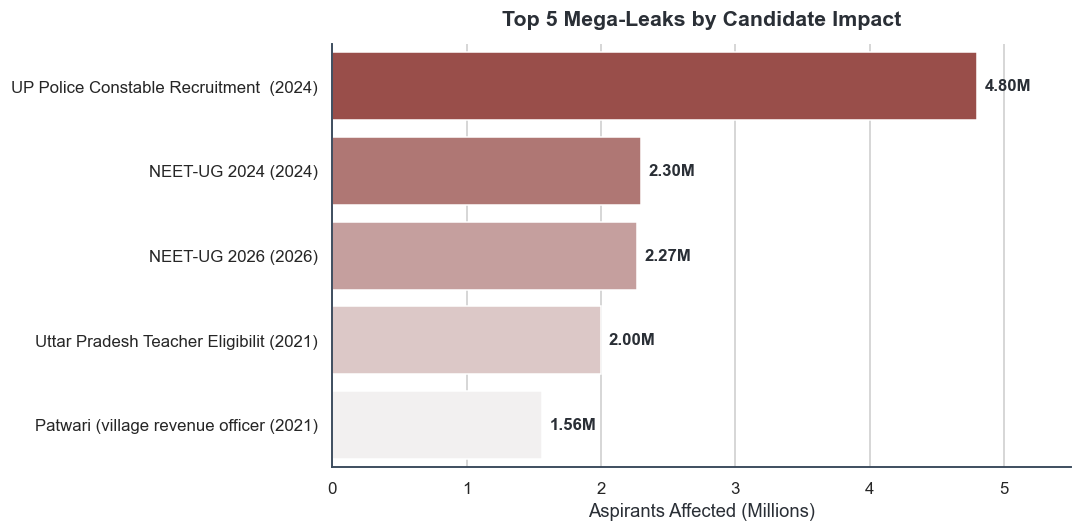

,exam_name,year,state,aspirants_affected,action_taken
89,UP Police Constable Recruitment Exam 2024,2024,Uttar Pradesh,4800000.0,Arrests-FIR + Exam cancelled + Probe (STF) + R...
92,NEET-UG 2024,2024,All India,2300000.0,Arrests-FIR + Probe (CBI/SIT) + Retest
107,NEET-UG 2026,2026,All India,2270000.0,Arrests-FIR + Exam cancelled + Probe (CBI/SIT)...
57,Uttar Pradesh Teacher Eligibility Test (UPTET)...,2021,Uttar Pradesh,1999000.0,Arrests-FIR + Exam cancelled
56,Patwari (village revenue officer) recruitment ...,2021,Rajasthan,1562000.0,Arrests-FIR


In [25]:
mega_leaks = df.nlargest(5, 'aspirants_affected')[['exam_name', 'year', 'state', 'aspirants_affected', 'action_taken']].copy()
mega_leaks['affected_millions'] = mega_leaks['aspirants_affected'] / 1e6
mega_leaks['short_label'] = mega_leaks['exam_name'].str.slice(0,32) + ' (' + mega_leaks['year'].astype(str) + ')'

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=mega_leaks, y='short_label', x='affected_millions', hue='short_label',
                  palette=seq_palette(5), legend=False)
plt.title('Top 5 Mega-Leaks by Candidate Impact', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Aspirants Affected (Millions)'); plt.ylabel('')
for p in ax.patches:
    ax.annotate(f'{p.get_width():.2f}M', (p.get_width(), p.get_y()+p.get_height()/2.),
                ha='left', va='center', fontsize=11, fontweight='bold', xytext=(5,0), textcoords='offset points')
plt.xlim(0, 5.5)
plt.gca().spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()
mega_leaks[['exam_name','year','state','aspirants_affected','action_taken']]

**Result Summary -- Geographic & Administrative Distribution.** State-level bodies account for 80% of all
incidents (88 of 110) versus 20% for Central bodies (22 of 110) -- and those state-level incidents carry the
larger share of human impact too (~16.16M vs ~6.35M aspirants). **Uttar Pradesh** leads in candidate impact
(8.02M across 12 incidents) despite ranking third in frequency; **Madhya Pradesh** (13 incidents, heavily
Vyapam-driven) and **Rajasthan** (11 incidents) lead in frequency. The five largest single incidents --
topped by the 2024 UP Police Constable exam (4.8M candidates) -- together affected **12.9M+ aspirants**,
illustrating how a handful of mega-recruitment exams concentrate most of the human impact even though they're
a small fraction of total incidents. Notably, the Rajasthan Patwari leak (2021) is the only mega-leak of the
five where the exam was **not** cancelled despite arrests being made.

### 6.4 Law Enforcement & Accountability Gap <a id='6.4'></a>
**6.4.1 Government response strategy**

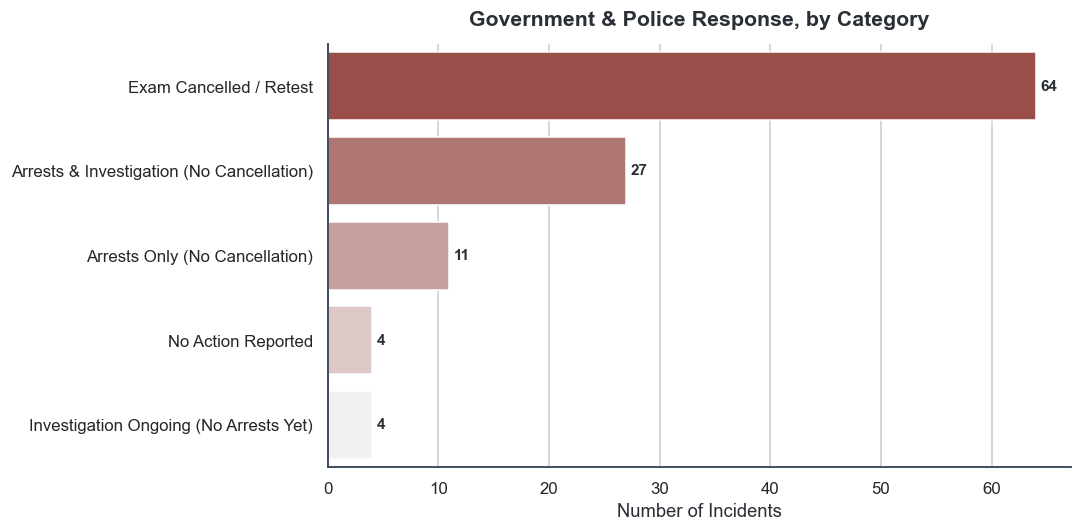

action_summary
Exam Cancelled / Retest                      58.2
Arrests & Investigation (No Cancellation)    24.5
Arrests Only (No Cancellation)               10.0
No Action Reported                            3.6
Investigation Ongoing (No Arrests Yet)        3.6
Name: proportion, dtype: float64

In [26]:
plt.figure(figsize=(10, 5))
action_order = df['action_summary'].value_counts().index
ax = sns.countplot(data=df, y='action_summary', order=action_order, hue='action_summary',
                    palette=seq_palette(df['action_summary'].nunique()), legend=False)
plt.title('Government & Police Response, by Category', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Number of Incidents'); plt.ylabel('')
annotate_bars(ax, fmt='{:.0f}', orient='h')
plt.gca().spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()
df['action_summary'].value_counts(normalize=True).mul(100).round(1)

**Reading this:** the exam is cancelled or a retest ordered in 58.2% of incidents (64 of 110) -- the
default response. In a further 24.5% (27 of 110), arrests were made *and* an investigation opened, but the
exam was allowed to stand; add the 10.0% (11 of 110) where arrests happened with no formal investigation
noted, and **34.5% of all incidents (38 of 110) saw some enforcement action without the exam itself ever
being cancelled** -- i.e. the underlying result was allowed to stand despite a confirmed or alleged breach.

**6.4.2 Arrests vs. convictions -- by era**

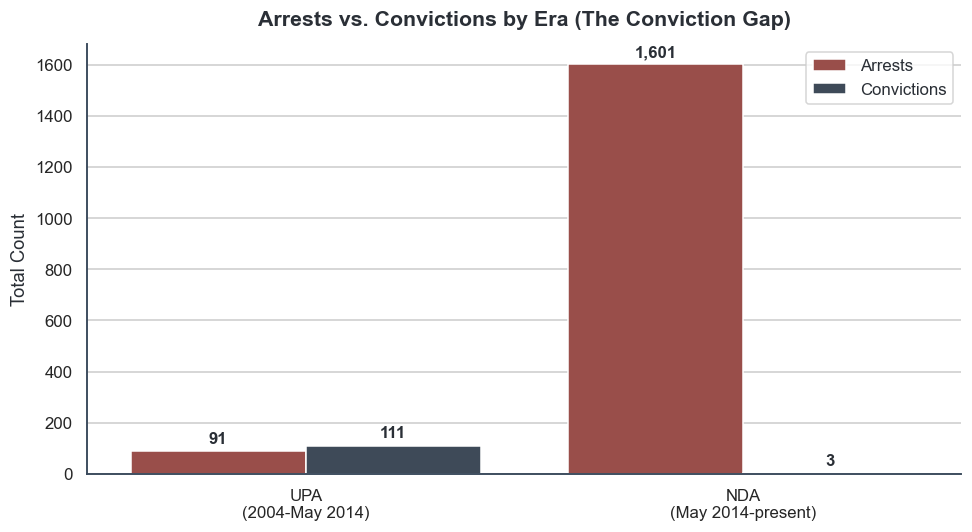

In [27]:
era_acc = df.groupby('era').agg(Arrests=('arrests','sum'), Convictions=('convictions','sum')).reset_index()
era_acc_melted = pd.melt(era_acc, id_vars=['era'], value_vars=['Arrests','Convictions'],
                          var_name='Metric', value_name='Count')

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=era_acc_melted, x='era', y='Count', hue='Metric', order=era_order,
                  palette=[C['primary'], C['secondary']])
plt.title('Arrests vs. Convictions by Era (The Conviction Gap)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel(''); plt.ylabel('Total Count')
ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(['UPA\n(2004-May 2014)', 'NDA\n(May 2014-present)'])
plt.legend(title='', fontsize=11)
for container in ax.containers:
    labels = [f'{int(v.get_height()):,}' if v.get_height() > 0 else '' for v in container]
    ax.bar_label(container, labels=labels, padding=3, fontweight='bold', fontsize=11)
plt.gca().spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

> **Why does UPA show more convictions (111) than arrests (91)?** This looks like it should be
> impossible -- convictions normally follow arrests -- so it's worth showing the evidence rather than
> asking you to take it on faith.


>**Data Limitation:** Arrest and conviction information was extracted from publicly available reports. Some incidents report convictions without recording earlier arrests, while others report arrests but not subsequent judicial outcomes. Therefore, arrest and conviction statistics should be interpreted as reported values rather than a complete legal  history.

In [28]:
upa_conv_rows = df[(df['era'].str.startswith('UPA')) & (df['convictions'].notna())][
    ['incident_id','date','exam_name','arrests','convictions']]
upa_conv_rows

,incident_id,date,exam_name,arrests,convictions
2,PL-0003,2008-01-01,Vyapam Patwari Recruitment Examination 2008,NaN,10.0
4,PL-0005,2010-06-06,RRB Mumbai 2010 recruitment exam (Assistant Lo...,15.0,10.0
6,PL-0007,2011-02-17,CBSE Class 10 & Class 12 Board Examinations 2011,3.0,4.0
15,PL-0016,2012-06-01,Jammu & Kashmir Common Entrance Test (JKCET) 2...,NaN,11.0
17,PL-0018,2012-09-30,Vyapam Police Constable Recruitment Examinatio...,NaN,11.0
18,PL-0019,2013-01-01,Agricultural Development Officer & combined co...,NaN,34.0
19,PL-0020,2013-01-01,Vyapam Police Constable Recruitment Examinatio...,NaN,31.0


In [29]:
no_arrest_on_file = upa_conv_rows[upa_conv_rows['arrests'].isna()]
print(f"{len(no_arrest_on_file)} of the {len(upa_conv_rows)} UPA incidents with conviction data have NO arrests figure on file.")
print(f"Those {len(no_arrest_on_file)} incidents alone contribute {no_arrest_on_file['convictions'].sum():.0f} of UPA's 111 convictions "
      f"({no_arrest_on_file['convictions'].sum()/111*100:.0f}%) -- with 0 counted toward the arrests total, since .sum() skips NaN.")

5 of the 7 UPA incidents with conviction data have NO arrests figure on file.
Those 5 incidents alone contribute 97 of UPA's 111 convictions (87%) -- with 0 counted toward the arrests total, since .sum() skips NaN.


**The mechanism:** it's a missing-data artifact, not a logical impossibility or a charting bug. Three of
the five zero-arrest rows above are Vyapam-linked incidents (2008, 2012, 2013) whose convictions were secured
years later as CBI/SIT prosecutions concluded -- news coverage of the eventual conviction count didn't always
circle back to attach a specific arrest figure to that particular incident-year. In India's justice system a
conviction cannot occur without a prior arrest/charge, so real arrests almost certainly happened for these
rows -- they just were never captured as a number in this dataset's sourcing. Only one incident (PL-0007, CBSE
2011) shows a genuine same-row excess (3 arrests -> 4 convictions), a small and plausible gap consistent with
a slightly wider net of people ultimately convicted than were in the initial arrest tally reported at the
time. **Read the era-level arrests/convictions comparison as two independently-sparse counts, not a matched
pair** -- exactly the same caution as every other total in this section.

In [30]:
total_arrests = df['arrests'].sum()
n_arrest_reports = df['arrests_reported'].sum()
total_convictions = df['convictions'].sum()
n_conviction_reports = df['convictions_reported'].sum()
print(f'Total arrests on record: {total_arrests:,.0f}  (reported in {n_arrest_reports} of 110 incidents)')
print(f'  -> mean arrests PER INCIDENT WHERE REPORTED: {total_arrests/n_arrest_reports:.1f}')
print(f'  -> mean arrests per incident IF averaged across all 110 (misleading): {total_arrests/110:.1f}')
print()
print(f'Total convictions on record: {total_convictions:,.0f}  (reported in only {n_conviction_reports} of 110 incidents)')
print(f'Incidents with ANY conviction data disclosed: {n_conviction_reports}/110 ({n_conviction_reports/110*100:.0f}%)')

Total arrests on record: 1,692  (reported in 63 of 110 incidents)
  -> mean arrests PER INCIDENT WHERE REPORTED: 26.9
  -> mean arrests per incident IF averaged across all 110 (misleading): 15.4

Total convictions on record: 114  (reported in only 10 of 110 incidents)
Incidents with ANY conviction data disclosed: 10/110 (9%)


**Result Summary -- Law Enforcement & Accountability.** The UPA era logged 91 arrests against 111
convictions -- not evidence of convictions outrunning arrests in reality, but of five Vyapam-and-adjacent
incidents whose conviction counts made it into press reporting while their arrest counts didn't (see above).
The NDA era logged a much larger 1,601 arrests against just **3** convictions -- and here the sparsity cuts
the other way, likely understating true convictions rather than overstating them, since NDA-era prosecutions
for recent incidents are less likely to have concluded yet. Two things are nonetheless real and worth holding
onto: **(1)** the modern era's enforcement response is large in absolute terms, and **(2)** the conviction
pipeline has essentially stalled -- but a fairer per-incident framing is **~27 arrests for each of the 63 incidents that report a
number**, not "~15 per exam averaged across all 110," since 47 incidents never report an arrest figure at
all. The conviction side is starker still: only **10 of 110 incidents (9%)** disclose any conviction outcome
whatsoever -- for the other 91%, the public record simply goes quiet after the initial arrests and headlines.
That silence is itself part of the finding, not just a data-quality footnote.

**6.4.3 How solid is this record? Source confidence & leak-status verification**
The cleaning steps standardized `leak_status`, but the original notebook never actually visualized it (or the `confidence` column) -- both speak directly to how much weight the rest of this analysis can bear.

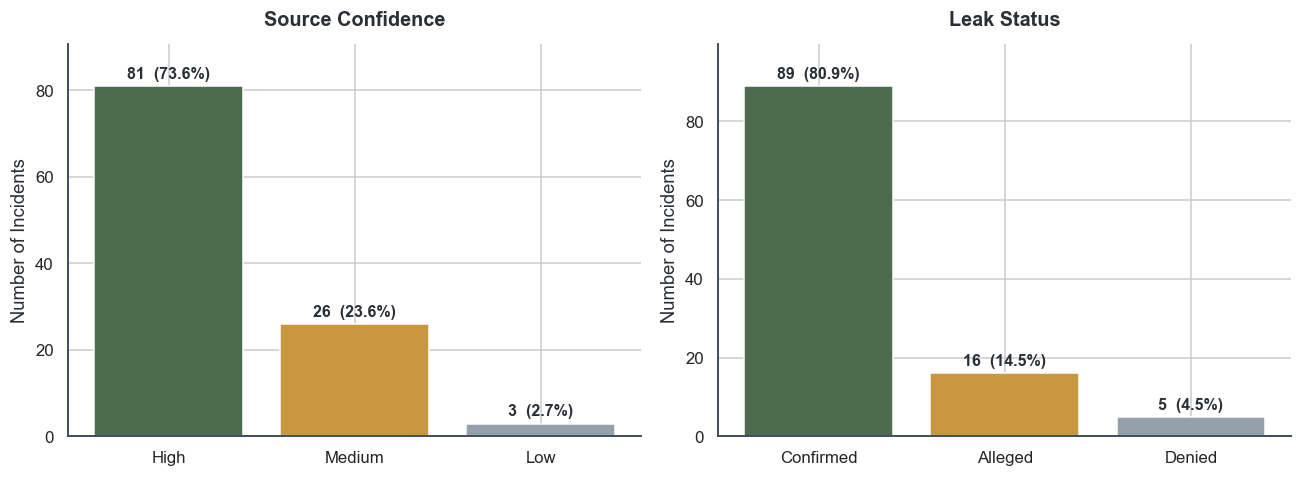

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

conf_order = ['High', 'Medium', 'Low']
conf_counts = df['confidence'].value_counts().reindex(conf_order)
conf_colors = [C['good'], C['accent'], C['muted']]
bars0 = axes[0].bar(conf_counts.index, conf_counts.values, color=conf_colors, edgecolor='white', linewidth=1)
axes[0].set_title('Source Confidence', fontsize=13, fontweight='bold', pad=12)
axes[0].set_ylabel('Number of Incidents')
for b, v in zip(bars0, conf_counts.values):
    axes[0].annotate(f'{v}  ({v/len(df)*100:.1f}%)', (b.get_x()+b.get_width()/2, v),
                      ha='center', va='bottom', fontsize=10.5, fontweight='bold', xytext=(0,3), textcoords='offset points')

status_order = df['leak_status'].value_counts().index
status_colors_map = {'Confirmed': C['good'], 'Alleged': C['accent'], 'Denied': C['muted']}
status_counts = df['leak_status'].value_counts()
status_colors = [status_colors_map.get(s, C['muted']) for s in status_order]
bars1 = axes[1].bar(status_order, status_counts.values, color=status_colors, edgecolor='white', linewidth=1)
axes[1].set_title('Leak Status', fontsize=13, fontweight='bold', pad=12)
axes[1].set_ylabel('Number of Incidents')
for b, v in zip(bars1, status_counts.values):
    axes[1].annotate(f'{v}  ({v/len(df)*100:.1f}%)', (b.get_x()+b.get_width()/2, v),
                      ha='center', va='bottom', fontsize=10.5, fontweight='bold', xytext=(0,3), textcoords='offset points')

for ax in axes:
    ax.spines[['top','right']].set_visible(False)
    ax.margins(y=0.12)
plt.tight_layout()
plt.show()

**Reading this:** 73.6% of incidents are rated high-confidence by the compiler (multiple corroborating
sources), and 80.9% are Confirmed rather than Alleged or Denied -- a solid evidentiary base overall, but worth
knowing that roughly 1 in 4 incidents rests on thinner sourcing, and the 5 "Denied" cases mean the underlying
authority disputes the incident occurred at all. None of the charts above distinguish confidence level, so
treat single specific data points (an exact arrest count, a specific death toll) as more provisional than the
incident-level counts that drive most of this notebook.

## 7. Limitations & Caveats <a id='7'></a>

- **This is a press-sourced compilation, not an official government count.** It documents incidents that
  reached public reporting; leaks that were never publicised (especially in earlier, pre-social-media years)
  are not represented. Every count in this notebook is a documented floor, not a ceiling.
- **Sparse reporting on magnitude fields.** `arrests` (57%), `aspirants_affected` (40%), `linked_deaths` (4%)
  and especially `convictions` (9%) are reported for a minority of incidents. All averages built on these
  fields describe *"where reported,"* not the full 110.
- **Era comparisons are confounded by reporting growth.** Section 6.1's UPA-vs-NDA gap likely reflects both
  a genuine rise in incidents *and* a rise in detection/reporting capacity -- the dataset can't separate these.
- **Categorization involves judgment calls.** `exam_category` and `standardized_exam_name` are keyword-rule
  classifications (section 4). We improved coverage substantially (the "Other" bucket fell from 25.5% to
  5.5%), but a few borderline exams (e.g. "Agricultural Development Officer") remain genuinely ambiguous.
- **`linked_deaths` figures are contested.** Where reported, several sources explicitly flag these as press
  tallies rather than officially adjudicated causal counts -- worth extra caution before quoting standalone.

## 8. Overall Conclusion <a id='8'></a>

### Executive Narrative
Across 110 documented incidents spanning 2004-2026, India's exam-paper-leak problem has scaled sharply since
2020 -- whether from a genuine rise in incidents, a rise in how many get reported, or (most plausibly) both.
The affected population is enormous: 22.5M+ aspirants across just the 44 incidents that report a figure.

### Key Findings by Pillar
1. **Temporal:** 63 of 110 incidents (57%) occurred in 2021-2026 alone; 2022 was the peak year (15). The
   UPA-vs-NDA rate gap (~2.4/yr vs ~7.1/yr) is real in this dataset but confounded by reporting growth --
   read as a documentation trend, not a governance scorecard.
2. **Sector:** Civil Services/Admin (29.1%), Medical/Healthcare (18.2%) and Police/Defence (16.4%) sectors
   draw organized targeting because they offer secure, high-competition government employment. NEET/Pre-
   Medical Entrance is the single most recurring exam lineage (13 incidents since the 2000s).
3. **Geographic:** State-level boards run 80% of all incidents and carry the larger human-impact share
   (~16.16M vs ~6.35M aspirants) -- the structural fix likely runs through state PSCs and staff-selection
   commissions even though central exams draw the most media attention. Vyapam (10 incidents) and CBSE (9)
   are the most-implicated single institutions.
4. **Accountability:** Enforcement is front-loaded and largely opaque after that: arrests happen often
   (averaging ~27 per incident where reported), but conviction outcomes are disclosed for only 9% of all
   incidents. In 34.5% of cases, some enforcement action occurred but the exam itself was never cancelled.

### Core Thesis
> Paper leaks in India have moved from isolated, opportunistic cheating toward a recurring, structurally
> concentrated pattern -- centered on state-level recruitment boards and a small number of repeat institutions
> -- where visible enforcement activity (arrests, FIRs, probes) coexists with almost no visible judicial
> follow-through. The data supports this pattern clearly; it does not, on its own, support attributing the
> trend primarily to any single government, sector actor, or cause.